# 01 — EDA de PM2.5 diario en el Valle de Aburrá

Datos: `data/processed/pm25_diario.csv` (IDEAM-SISAIRE + SIATA, promedios de 24 h con ≥ 75 % de horas válidas; meteorología Open-Meteo/ERA5).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.config import PROCESSED_DIR, CLASSES, PM25_DAILY_LIMIT
from src.data.features import load_daily
daily = load_daily()
stations = pd.read_csv(PROCESSED_DIR / 'estaciones.csv', dtype={'estacion_id': str})
report = json.loads((PROCESSED_DIR / 'clean_report.json').read_text(encoding='utf-8'))
report

{'horas_sisaire': 1042146,
 'meses_estacion_escala_inconsistente': 715,
 'horas_en_meses_inconsistentes': 404789,
 'horas_fuera_de_rango': 0,
 'horas_rellenadas_siata': 46117,
 'dias_descartados_menos_75pct': 1922,
 'estaciones_descartadas_poca_historia': ['29507', '30731', '32034'],
 'estaciones_finales': 25,
 'dias_estacion_finales': 28304,
 'distribucion_clases': {'normal': 27996, 'alerta': 307, 'critico': 1}}

## Cobertura por estación y año (días válidos)

In [2]:
cov = daily.assign(anio=daily.fecha.dt.year).pivot_table(index='estacion_id', columns='anio', values='pm25', aggfunc='size').fillna(0).astype(int)
cov.index = cov.index.map(stations.set_index('estacion_id')['nombre'])
cov

anio,2020,2021,2022,2023,2024,2025
estacion_id,,,,,,
CASA JUSTICIA,331,347,349,333,361,342
TRÁFICO CENTRO,329,332,342,344,351,345
I.E. CONCEJO MUNICIPAL,323,351,344,341,351,352
CORPORACIÓN LASALLISTA,323,320,121,0,0,0
TANQUES LA YE,322,352,349,338,93,0
TRÁFICO SUR,339,305,349,0,0,0
ESCUELA JOAQUÍN A.,0,0,0,144,349,347
TORRE SOCIAL,0,0,0,145,357,348
CIUDADELA EDUCATIVA,0,0,0,148,353,357


Las estaciones con huecos en 2020–2023 son las que SISAIRE reporta con escala inconsistente; esos meses se descartaron (ver `src/data/clean.py`).

## Serie de tiempo (mediana diaria entre estaciones) con el límite de 37 µg/m³

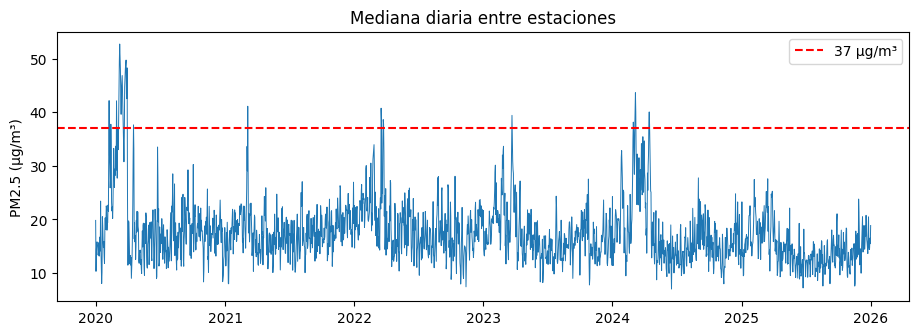

In [3]:
med = daily.groupby('fecha').pm25.median()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(med.index, med.values, lw=0.7)
ax.axhline(PM25_DAILY_LIMIT, color='red', ls='--', label='37 µg/m³')
ax.set_ylabel('PM2.5 (µg/m³)'); ax.legend(); ax.set_title('Mediana diaria entre estaciones'); plt.show()

## Distribución de clases por mes
Deben aparecer las temporadas críticas (feb–abr y, en menor medida, oct–nov).

fecha     1     2     3     4     5     6     7     8     9     10    11    12
clase                                                                         
normal  2275  1964  1945  2171  2191  2179  2288  2638  2577  2672  2544  2552
alerta    12    61   160    59     0     2     0     2     2     2     1     6


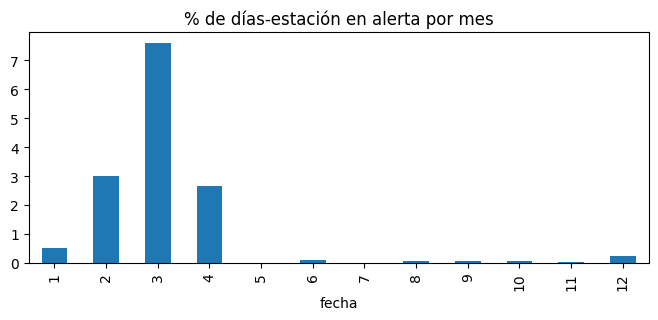

In [4]:
ct = pd.crosstab(daily.fecha.dt.month, daily.clase)[CLASSES[:2]]
print(ct.T)
(ct['alerta'] / ct.sum(axis=1) * 100).plot.bar(figsize=(8, 3), title='% de días-estación en alerta por mes'); plt.show()

In [5]:
daily.clase.value_counts(normalize=True).round(4)

clase
normal     0.9891
alerta     0.0108
critico    0.0000
Name: proportion, dtype: float64

## Lluvia y viento vs PM2.5 del día siguiente

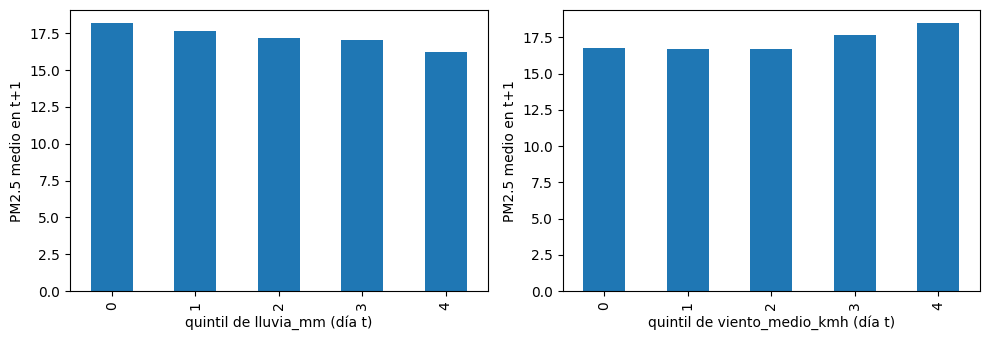

,pm25,lluvia_mm,viento_medio_kmh,pm25_manana
pm25,1.00,-0.00,0.04,0.74
lluvia_mm,-0.00,1.00,-0.58,-0.09
viento_medio_kmh,0.04,-0.58,1.00,0.08
pm25_manana,0.74,-0.09,0.08,1.00


In [6]:
from src.data.features import make_pairs
pairs = make_pairs(daily)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ['lluvia_mm', 'viento_medio_kmh']):
    q = pd.qcut(pairs[col].rank(method='first'), 5, labels=False)
    pairs.groupby(q).pm25_manana.mean().plot.bar(ax=ax)
    ax.set_xlabel(f'quintil de {col} (día t)'); ax.set_ylabel('PM2.5 medio en t+1')
plt.tight_layout(); plt.show()
pairs[['pm25', 'lluvia_mm', 'viento_medio_kmh', 'pm25_manana']].corr(method='spearman').round(2)

**Lectura:** la persistencia domina: la correlación de Spearman entre el PM2.5 de hoy y el de mañana es 0,74. La lluvia del día *t* se asocia apenas con menos PM2.5 en *t+1* (ρ = −0,09). El viento de ERA5 casi no se relaciona (ρ = +0,08), probablemente porque el reanálisis (~10 km) no resuelve la circulación dentro del valle. Las clases están muy desbalanceadas: ~1 % de días-estación en alerta y un único día crítico en 2020–2025.